In [1]:
!git clone https://github.com/ultralytics/yolov5.git

Cloning into 'yolov5'...
remote: Enumerating objects: 18875, done.
remote: Counting objects: 100% (409/409), done.
remote: Compressing objects: 100% (75/75), done.
remote: Total 18875 (delta 351), reused 334 (delta 334), pack-reused 18466 (from 2)
Receiving objects: 100% (18875/18875), 17.74 MiB | 18.09 MiB/s, done.
Resolving deltas: 100% (12888/12888), done.


In [2]:
%cd yolov5

/content/yolov5


In [3]:
!pip install -qr requirements.txt
import torch
from IPython.display import Image, clear_output
print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

Setup complete. Using torch 2.14.1+cu130 _CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=14912MB, multi_processor_count=40, uuid=39e973df-c550-8cc4-9993-d07993642af1, pci_bus_id=0, pci_device_id=4, pci_domain_id=0, L2_cache_size=4MB)


In [4]:
! pwd

/content/yolov5


In [5]:
%cd /content

/content


In [6]:
!curl -L "https://github.com/18401172024/SignLanguageDetection3/raw/refs/heads/main/Sign_language_data%20(3).zip" > SignData.zip; unzip SignData.zip; rm SignData.zip


Streaming output truncated to the last 5000 lines.
  inflating: yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_c_right_seg_4_cropped_jpeg.rf.654fb812d56cf5d14757cbc61ffbec93.jpg  
  inflating: yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_c_top_seg_4_cropped_jpeg.rf.41bb40dfe840a63bc60bc4db19bdb26d.jpg  
  inflating: yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_d_dif_seg_4_cropped_jpeg.rf.f3cc8affb7928b7879d578b9c3fd7043.jpg  
  inflating: yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_e_dif_seg_4_cropped_jpeg.rf.e15e033c906aea5ecf9852d0524eca4d.jpg  
  inflating: yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_e_right_seg_4_cropped_jpeg.rf.f2b9655aa725f1c27e214ac7d03189fb.jpg  
  inflating: yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_e_top_seg_1_cropped_jpeg.rf.b56b39491cc9693796eff0be81273cb9.jpg  
  inflating: yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_e_to

In [7]:
%cat /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 36
names: ['A', 'B', 'C', 'D', 'E', 'Eight', 'F', 'Five', 'Four', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'Nine', 'O', 'One', 'P', 'Q', 'R', 'S', 'Seven', 'Six', 'T', 'Three', 'Two', 'U', 'V', 'W', 'X', 'Y', 'Z', 'Zero']

roboflow:
  workspace: shikha-tiwari-vrwzs
  project: yolovssignlanguagedetection
  version: 2
  license: CC BY 4.0
  url: https://universe.roboflow.com/shikha-tiwari-vrwzs/yolovssignlanguagedetection/dataset/2

In [8]:
import yaml

with open("/content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml", 'r') as stream:
    num_classes = str(yaml.safe_load(stream)['nc'])

print(num_classes)

36


In [9]:
%cat /content/yolov5/models/yolov5s.yaml

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

# Ultralytics YOLOv5s object detection model with P3/8 - P5/32 outputs
# Model docs: https://docs.ultralytics.com/models/yolov5
# Task docs: https://docs.ultralytics.com/tasks/detect
# Example usage: python train.py --cfg yolov5s.yaml --data coco.yaml

# Parameters
nc: 80 # number of classes
depth_multiple: 0.33 # model depth multiple
width_multiple: 0.50 # layer channel multiple
anchors:
  - [10, 13, 16, 30, 33, 23] # P3/8 small-object anchors
  - [30, 61, 62, 45, 59, 119] # P4/16 medium-object anchors
  - [116, 90, 156, 198, 373, 326] # P5/32 large-object anchors

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [
    [-1, 1, Conv, [64, 6, 2, 2]], # 0-P1/2
    [-1, 1, Conv, [128, 3, 2]], # 1-P2/4
    [-1, 3, C3, [128]],
    [-1, 1, Conv, [256, 3, 2]], # 3-P3/8
    [-1, 6, C3, [256]],
    [-1, 1, Conv, [512, 3, 2]], # 5-P4/16
    [-1, 9, C3, [512]],
    [-1, 1, Conv, [1024, 3, 2]], # 7-P5/32
    [-1

In [11]:
from IPython.core.magic import register_line_cell_magic

@register_line_cell_magic
def writetemplate(line, cell):
    with open(line, 'w') as f:
        f.write(cell.format(**globals()))

In [12]:
%%writetemplate /content/yolov5/models/custom_yolov5s.yaml

# Parameters
nc: {num_classes} # number of classes
depth_multiple: 0.33 # model depth multiple
width_multiple: 0.50 # layer channel multiple
anchors:
  - [10, 13, 16, 30, 33, 23] # P3/8
  - [30, 61, 62, 45, 59, 119] # P4/16
  - [116, 90, 156, 198, 373, 326] # P5/32

# YOLOv5 v6.0 backbone
backbone:
  # [from, number, module, args]
  [
    [-1, 1, Conv, [64, 6, 2, 2]], # 0-P1/2
    [-1, 1, Conv, [128, 3, 2]], # 1-P2/4
    [-1, 3, C3, [128]],
    [-1, 1, Conv, [256, 3, 2]], # 3-P3/8
    [-1, 6, C3, [256]],
    [-1, 1, Conv, [512, 3, 2]], # 5-P4/16
    [-1, 9, C3, [512]],
    [-1, 1, Conv, [1024, 3, 2]], # 7-P5/32
    [-1, 3, C3, [1024]],
    [-1, 1, SPPF, [1024, 5]], # 9
  ]

# YOLOv5 v6.0 head
head: [
    [-1, 1, Conv, [512, 1, 1]],
    [-1, 1, nn.Upsample, [None, 2, "nearest"]],
    [[-1, 6], 1, Concat, [1]], # cat backbone P4
    [-1, 3, C3, [512, False]], # 13

    [-1, 1, Conv, [256, 1, 1]],
    [-1, 1, nn.Upsample, [None, 2, "nearest"]],
    [[-1, 4], 1, Concat, [1]], # cat backbone P3
    [-1, 3, C3, [256, False]], # 17 (P3/8-small)

    [-1, 1, Conv, [256, 3, 2]],
    [[-1, 14], 1, Concat, [1]], # cat head P4
    [-1, 3, C3, [512, False]], # 20 (P4/16-medium)

    [-1, 1, Conv, [512, 3, 2]],
    [[-1, 10], 1, Concat, [1]], # cat head P5
    [-1, 3, C3, [1024, False]], # 23 (P5/32-large)

    [[17, 20, 23], 1, Detect, [nc, anchors]], # Detect(P3, P4, P5)
  ]

In [13]:
!ls /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/

data.yaml  test  train	valid


In [15]:
import yaml
import os

dataset_path = "/content/yolovsSignLanguageDetection.v2i.yolov5pytorch"

yaml_path = os.path.join(dataset_path, "data.yaml")

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

data["path"] = dataset_path
data["train"] = "train/images"
data["val"] = "valid/images"
data["test"] = "test/images"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print("data.yaml updated successfully!")
print(data)

data.yaml updated successfully!
{'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 36, 'names': ['A', 'B', 'C', 'D', 'E', 'Eight', 'F', 'Five', 'Four', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'Nine', 'O', 'One', 'P', 'Q', 'R', 'S', 'Seven', 'Six', 'T', 'Three', 'Two', 'U', 'V', 'W', 'X', 'Y', 'Z', 'Zero'], 'roboflow': {'workspace': 'shikha-tiwari-vrwzs', 'project': 'yolovssignlanguagedetection', 'version': 2, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/shikha-tiwari-vrwzs/yolovssignlanguagedetection/dataset/2'}, 'path': '/content/yolovsSignLanguageDetection.v2i.yolov5pytorch'}


In [16]:
import os

dataset_path = "/content/yolovsSignLanguageDetection.v2i.yolov5pytorch"

folders = [
    "train/images",
    "train/labels",
    "valid/images",
    "valid/labels",
    "test/images",
    "test/labels"
]

for folder in folders:
    path = os.path.join(dataset_path, folder)

    if os.path.exists(path):
        print("FOUND:", folder, "| Files:", len(os.listdir(path)))
    else:
        print("MISSING:", folder)

FOUND: train/images | Files: 1761
FOUND: train/labels | Files: 1761
FOUND: valid/images | Files: 503
FOUND: valid/labels | Files: 503
FOUND: test/images | Files: 251
FOUND: test/labels | Files: 251


In [17]:
import yaml

yaml_path = "/content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml"

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

print("Number of classes:", data["nc"])
print("Total class names:", len(data["names"]))
print("Class names:", data["names"])

Number of classes: 36
Total class names: 36
Class names: ['A', 'B', 'C', 'D', 'E', 'Eight', 'F', 'Five', 'Four', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'Nine', 'O', 'One', 'P', 'Q', 'R', 'S', 'Seven', 'Six', 'T', 'Three', 'Two', 'U', 'V', 'W', 'X', 'Y', 'Z', 'Zero']


In [18]:
%%time
%cd /content/yolov5/

!python train.py \
    --img 416 \
    --batch 16 \
    --epochs 300 \
    --data /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml \
    --cfg ./models/yolov5s.yaml \
    --weights yolov5s.pt \
    --name sign_language_yolov5s_300

/content/yolov5
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1794046065.953242    1939 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout) 
wandb: WARNING W&B disabled due to login timeout.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin
train: weights=yolov5s.pt, cfg=./models/yolov5s.yaml, data=/content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=300, batch_size=16, imgsz=416, rect=False, resume=False, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=Fa

In [19]:
%load_ext tensorboard
%tensorboard --logdir runs

<IPython.core.display.Javascript object>

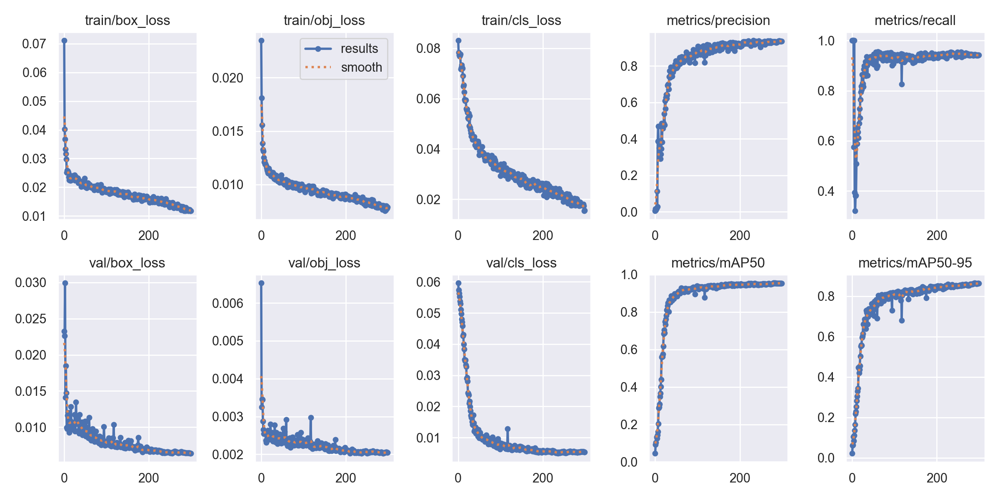

In [21]:
from utils.plots import plot_results
from IPython.display import Image, display

display(Image(
    filename='/content/yolov5/runs/train/sign_language_yolov5s_300/results.png',
    width=1000
))

In [24]:
!ls -R /content/yolov5/runs/train/

/content/yolov5/runs/train/:
sign_language_yolov5s_300

/content/yolov5/runs/train/sign_language_yolov5s_300:
confusion_matrix.png				    labels.jpg	  results.csv
events.out.tfevents.1794046098.71a24f371dc0.1939.0  opt.yaml	  results.png
F1_curve.png					    P_curve.png   weights
hyp.yaml					    PR_curve.png
labels_correlogram.jpg				    R_curve.png

/content/yolov5/runs/train/sign_language_yolov5s_300/weights:
best.pt  last.pt


In [26]:
%cd /content/yolov5/

!python val.py \
    --weights runs/train/sign_language_yolov5s_300/weights/best.pt \
    --data /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml \
    --imgsz 416 \
    --batch-size 16 \
    --task val

/content/yolov5
val: data=/content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml, weights=['runs/train/sign_language_yolov5s_300/weights/best.pt'], batch_size=16, imgsz=416, conf_thres=0.001, iou_thres=0.6, max_det=300, task=val, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-569-g9777cd00 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 68 layers, 7,107,217 parameters, 0 gradients, 16.1 GFLOPs
val: Scanning /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/valid/labels.cache... 503 images, 0 backgrounds, 0 corrupt
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 3% ──────────── 1/32 2.1s/it 0.6s<1:04Exception in thread Thread-2 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.

In [27]:
!ls -R /content/yolov5/runs/val/

/content/yolov5/runs/val/:
exp

/content/yolov5/runs/val/exp:
confusion_matrix.png  F1_curve.png  P_curve.png  PR_curve.png  R_curve.png


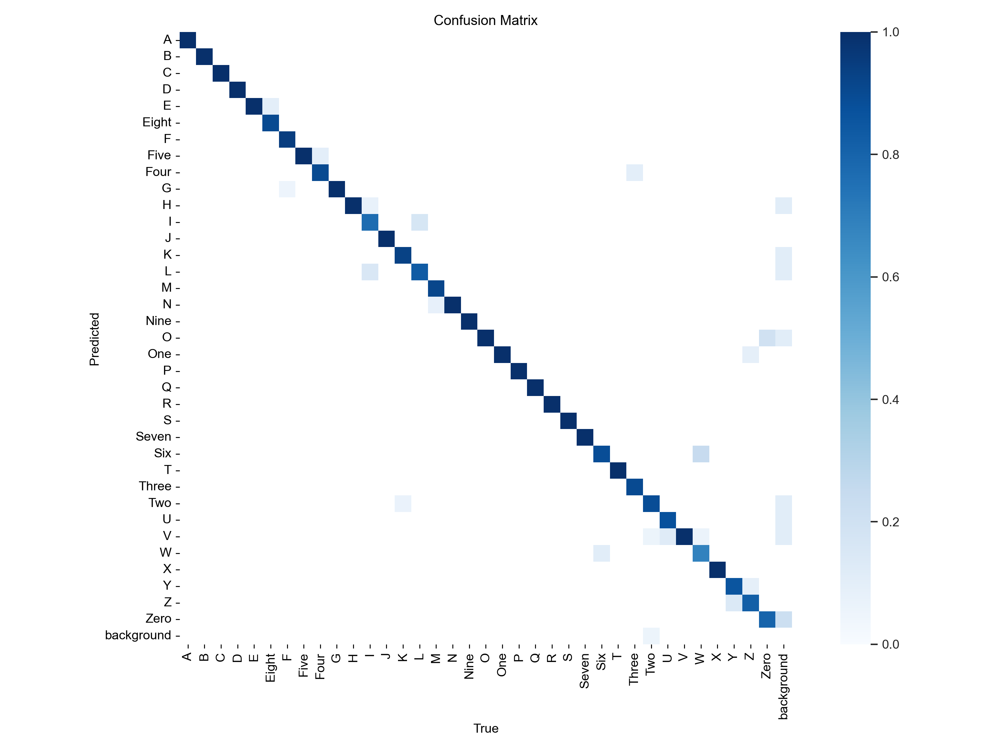

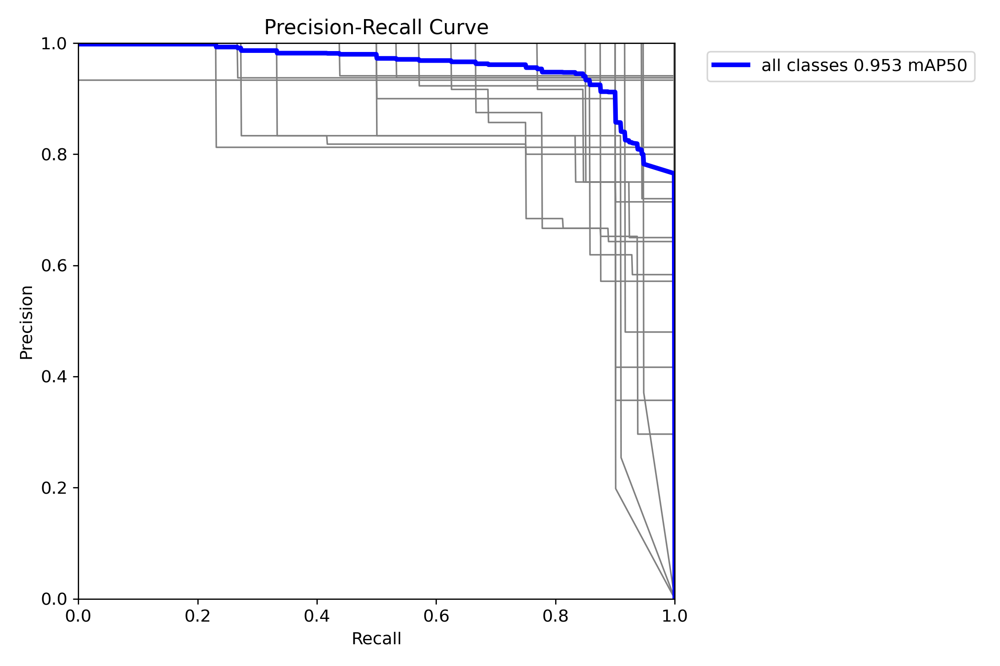

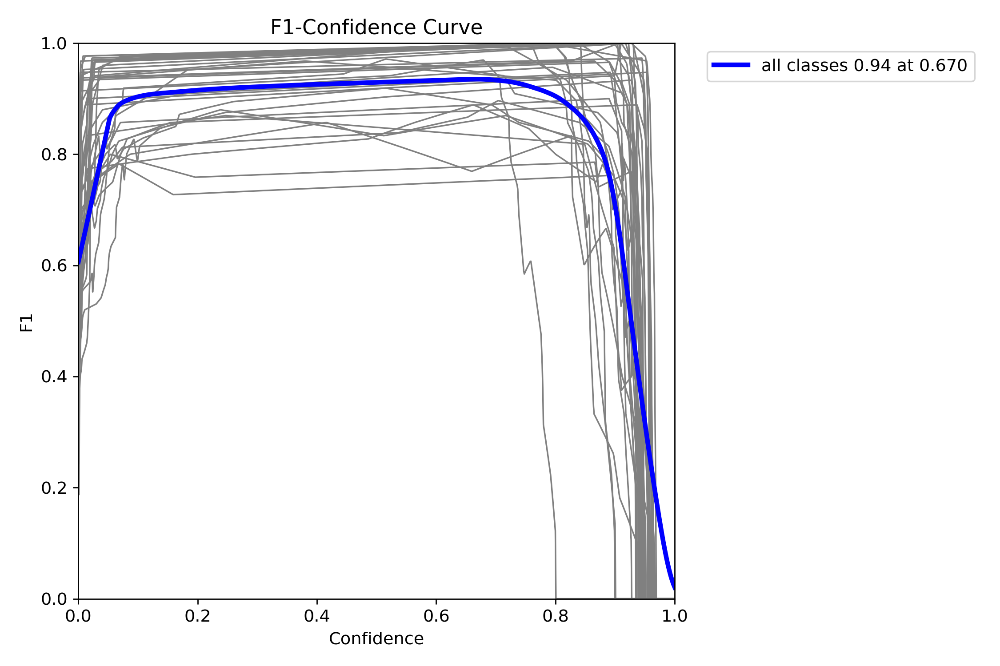

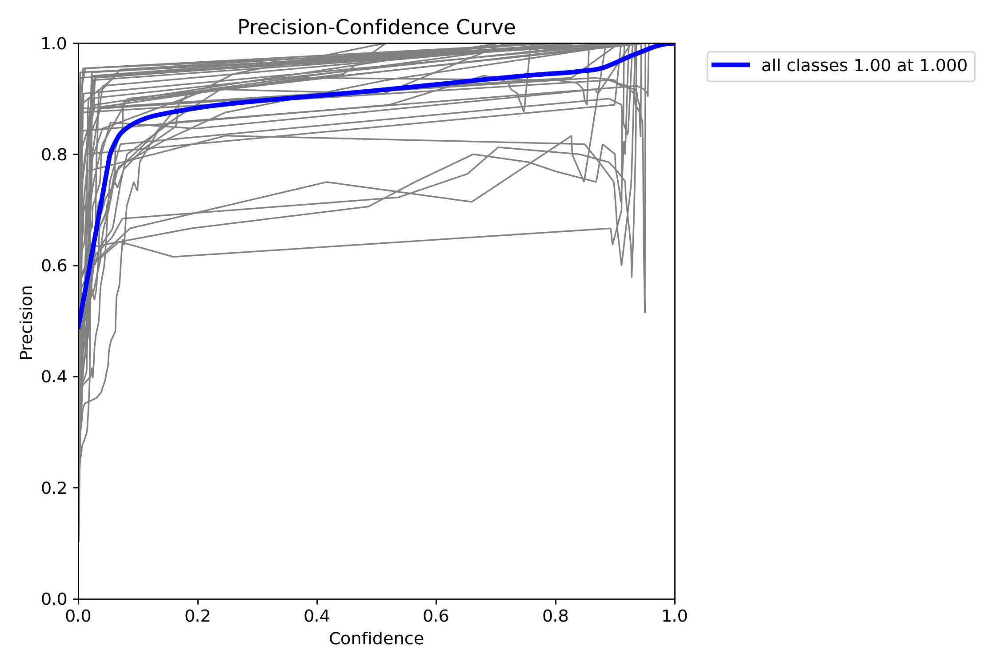

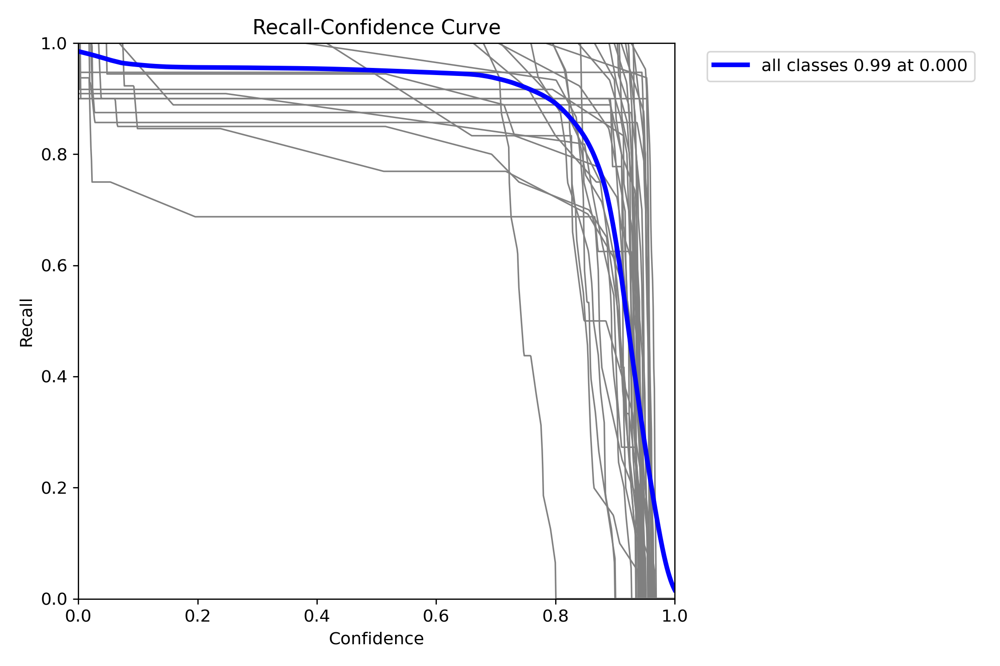

In [28]:
from IPython.display import Image, display

val_path = "/content/yolov5/runs/val/exp"

display(Image(filename=f"{val_path}/confusion_matrix.png", width=900))
display(Image(filename=f"{val_path}/PR_curve.png", width=900))
display(Image(filename=f"{val_path}/F1_curve.png", width=900))
display(Image(filename=f"{val_path}/P_curve.png", width=900))
display(Image(filename=f"{val_path}/R_curve.png", width=900))

In [29]:
import pandas as pd

df = pd.read_csv(
    "/content/yolov5/runs/train/sign_language_yolov5s_300/results.csv"
)

print(df.columns.tolist())
display(df.tail(5))

['               epoch', '      train/box_loss', '      train/obj_loss', '      train/cls_loss', '   metrics/precision', '      metrics/recall', '       metrics/mAP50', '    metrics/mAP50-95', '        val/box_loss', '        val/obj_loss', '        val/cls_loss', '               x/lr0', '               x/lr1', '               x/lr2']


,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,...,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
295,295,0.011889,0.007640,0.017832,0.93647,...,0.002058,0.005463,0.000298,0.000298,0.000298
296,296,0.012264,0.007995,0.018015,0.93584,...,0.002061,0.005435,0.000265,0.000265,0.000265
297,297,0.011791,0.007773,0.017466,0.93589,...,0.002056,0.005392,0.000232,0.000232,0.000232
298,298,0.011821,0.007767,0.015375,0.93567,...,0.002051,0.005326,0.000199,0.000199,0.000199
299,299,0.011828,0.007905,0.015602,0.93559,...,0.002052,0.005276,0.000166,0.000166,0.000166


In [30]:
import pandas as pd

df = pd.read_csv(
    "/content/yolov5/runs/train/sign_language_yolov5s_300/results.csv"
)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Show important metrics from the final epoch
metrics = [
    "epoch",
    "metrics/precision",
    "metrics/recall",
    "metrics/mAP50",
    "metrics/mAP50-95"
]

print("FINAL EPOCH METRICS:")
display(df[metrics].tail(1).round(4))

# Find the epoch with the highest mAP50-95
best_idx = df["metrics/mAP50-95"].idxmax()

print("BEST EPOCH METRICS:")
display(df.loc[[best_idx], metrics].round(4))

FINAL EPOCH METRICS:


,epoch,metrics/precision,metrics/recall,metrics/mAP50,metrics/mAP50-95
299,299,0.9356,0.942,0.9537,0.8639


BEST EPOCH METRICS:


,epoch,metrics/precision,metrics/recall,metrics/mAP50,metrics/mAP50-95
289,289,0.9334,0.9438,0.954,0.8654


In [31]:
%cd /content/yolov5/

!python val.py \
    --weights runs/train/sign_language_yolov5s_300/weights/best.pt \
    --data /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml \
    --imgsz 416 \
    --batch-size 16 \
    --task test

/content/yolov5
val: data=/content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml, weights=['runs/train/sign_language_yolov5s_300/weights/best.pt'], batch_size=16, imgsz=416, conf_thres=0.001, iou_thres=0.6, max_det=300, task=test, device=, workers=8, single_cls=False, augment=False, verbose=False, save_txt=False, save_hybrid=False, save_conf=False, save_json=False, project=runs/val, name=exp, exist_ok=False, half=False, dnn=False
YOLOv5 🚀 v7.0-569-g9777cd00 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 68 layers, 7,107,217 parameters, 0 gradients, 16.1 GFLOPs
test: Scanning /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/test/labels... 251 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 251/251 1.5Kit/s 0.2s
test: New cache created: /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/test/labels.cache
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 6% ╸─────────── 1/16 

In [32]:
%cd /content/yolov5/

!python detect.py \
    --weights runs/train/sign_language_yolov5s_300/weights/best.pt \
    --source /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images \
    --imgsz 416 \
    --conf-thres 0.67

/content/yolov5
detect: weights=['runs/train/sign_language_yolov5s_300/weights/best.pt'], source=/content/yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images, data=data/coco128.yaml, imgsz=[416, 416], conf_thres=0.67, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-569-g9777cd00 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 68 layers, 7,107,217 parameters, 0 gradients, 16.1 GFLOPs
image 1/251 /content/yolovsSignLanguageDetection.v2i.yolov5pytorch/test/images/hand1_0_bot_seg_4_cropped_jpeg.rf.ceab9997a308ee7a0199f3e4d9f5a7c8.jpg: 416x416 (no detections), 8.4ms
image 2/251 /content/yolovsSignLanguageDetection.v2i.yolov5p

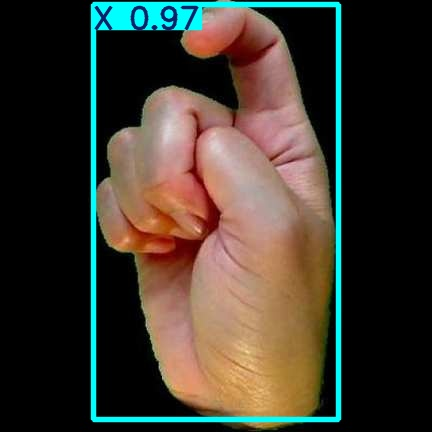

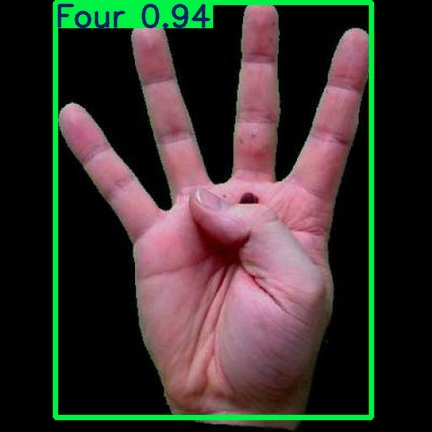

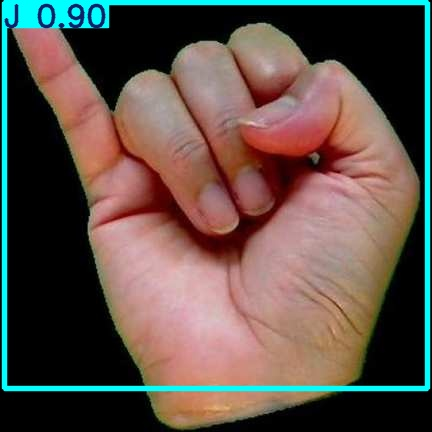

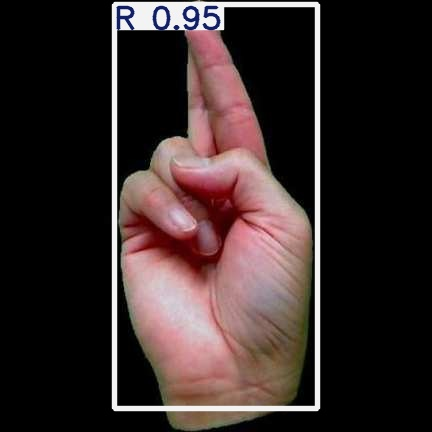

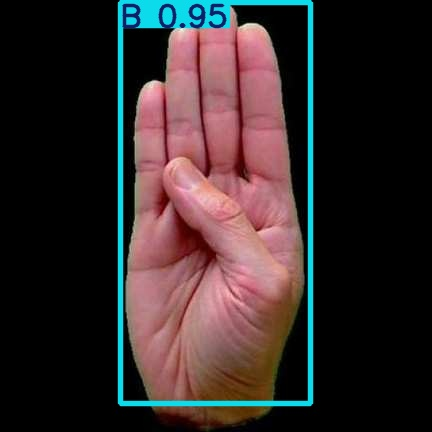

In [33]:
import glob
from IPython.display import display, Image

images = glob.glob(
    "/content/yolov5/runs/detect/exp/*"
)

for img in images[:5]:
    display(Image(filename=img, width=600))

In [34]:
import os
import shutil

# Create the project folder
project = "/content/SignLanguageDetection3"

folders = [
    "model",
    "notebooks",
    "data",
    "results/validation",
    "results/test"
]

for folder in folders:
    os.makedirs(os.path.join(project, folder), exist_ok=True)

# Copy the best trained model
best_model = "/content/yolov5/runs/train/sign_language_yolov5s_300/weights/best.pt"

assert os.path.exists(best_model), "ERROR: best.pt was not found!"

shutil.copy2(
    best_model,
    os.path.join(project, "model", "best.pt")
)

# Copy dataset configuration
data_yaml = "/content/yolovsSignLanguageDetection.v2i.yolov5pytorch/data.yaml"

assert os.path.exists(data_yaml), "ERROR: data.yaml was not found!"

shutil.copy2(
    data_yaml,
    os.path.join(project, "data", "data.yaml")
)

# Copy validation and test plots
plot_names = [
    "confusion_matrix.png",
    "F1_curve.png",
    "P_curve.png",
    "PR_curve.png",
    "R_curve.png"
]

result_folders = {
    "validation": "/content/yolov5/runs/val/exp",
    "test": "/content/yolov5/runs/val/exp2"
}

for result_type, source_folder in result_folders.items():
    for filename in plot_names:
        source = os.path.join(source_folder, filename)

        if os.path.exists(source):
            destination = os.path.join(
                project, "results", result_type, filename
            )
            shutil.copy2(source, destination)

print("Project files copied successfully!")

Project files copied successfully!


In [35]:
for root, dirs, files in os.walk("/content/SignLanguageDetection3"):
    for file in files:
        path = os.path.join(root, file)
        print(path, "-", round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

/content/SignLanguageDetection3/data/data.yaml - 0.0 MB
/content/SignLanguageDetection3/results/validation/confusion_matrix.png - 0.14 MB
/content/SignLanguageDetection3/results/validation/PR_curve.png - 0.11 MB
/content/SignLanguageDetection3/results/validation/P_curve.png - 0.22 MB
/content/SignLanguageDetection3/results/validation/F1_curve.png - 0.28 MB
/content/SignLanguageDetection3/results/validation/R_curve.png - 0.26 MB
/content/SignLanguageDetection3/results/test/confusion_matrix.png - 0.14 MB
/content/SignLanguageDetection3/results/test/PR_curve.png - 0.1 MB
/content/SignLanguageDetection3/results/test/P_curve.png - 0.26 MB
/content/SignLanguageDetection3/results/test/F1_curve.png - 0.28 MB
/content/SignLanguageDetection3/results/test/R_curve.png - 0.22 MB
/content/SignLanguageDetection3/model/best.pt - 13.84 MB
